# RAG-проект, КТ4: трансформация запросов, реранкинг и оценка качества ретрива

Тут пробую улучшить поиск из КТ3: перефразировать запрос, переранжировать выдачу cross-encoder'ом и через LLM, и смотрю, сколько это добавляет по времени. LLM везде Claude Sonnet 4.6.

In [1]:
%pip install -q chromadb rank-bm25 sentence-transformers scikit-learn pandas matplotlib "anthropic==0.125.0"

In [2]:
import warnings
warnings.filterwarnings('ignore')
import hashlib, json, os, re, time, pickle
os.environ['HF_HUB_DISABLE_PROGRESS_BARS'] = '1'
os.environ['TRANSFORMERS_VERBOSITY'] = 'error'
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
os.environ['HF_HUB_VERBOSITY'] = 'error'
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import anthropic
import chromadb
from rank_bm25 import BM25Okapi
from sklearn.feature_extraction.text import TfidfVectorizer
from sentence_transformers import SentenceTransformer, CrossEncoder
from transformers.utils import logging as hf_logging
hf_logging.disable_progress_bar()
import logging
logging.getLogger('sentence_transformers').setLevel(logging.ERROR)

%matplotlib inline
pd.set_option('display.width', 250)
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_colwidth', 70)

try:
    from google.colab import userdata
    os.environ['ANTHROPIC_API_KEY'] = userdata.get('ANTHROPIC_API_KEY')
except ImportError:
    pass

DATA = Path('data') if Path('data').exists() else Path('../data')
CACHE = DATA / 'kt4_cache'
(CACHE / 'llm').mkdir(parents=True, exist_ok=True)
DEVICE = 'cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu'

gold = json.load(open(DATA / 'gold_set.json', encoding='utf-8'))
val_q = [g for g in gold if g['split'] == 'val']
test_q = [g for g in gold if g['split'] == 'test']
used = {g['cand_id'] for g in gold}
extra = [c['question'] for c in json.load(open(DATA / 'candidates.json', encoding='utf-8')) if c['cand_id'] not in used]
TIMING_QUERIES = list(dict.fromkeys([g['question'] for g in gold] + [g['question_orig'] for g in gold] + extra))[:100]

TIMES_PATH = CACHE / 'timings.pkl'
TIMES = pickle.load(open(TIMES_PATH, 'rb')) if TIMES_PATH.exists() else {}
def measured(key, fn):
    if key not in TIMES:
        TIMES[key] = fn()
        pickle.dump(TIMES, open(TIMES_PATH, 'wb'))
    return TIMES[key]
print('val:', len(val_q), '| test:', len(test_q), '| уникальных запросов для замера задержки:', len(TIMING_QUERIES))

val: 35 | test: 15 | уникальных запросов для замера задержки: 100


## 0. Данные

Корпус и чанки те же, что в КТ3.

In [3]:
docs_clean, dup_map = pickle.load(open(DATA / 'kt2_cache' / 'clean_corpus.pkl', 'rb'))
chunks, _ = pickle.load(open(DATA / 'kt2_cache' / 'chunks_sentence_128.pkl', 'rb'))
STOP = set(open(DATA / 'stop_ru.txt', encoding='utf-8').read().split())
doc_text = {d['doc_id']: d['text'] for d in docs_clean}

def content_type(t):
    t = t.lower()
    if re.search(r'розыгрыш|победител|конкурс', t): return 'contest'
    if re.search(r'реклама|erid|igm\.gg|промокод', t): return 'ad'
    if re.search(r'получила скидку|покупаем за|акция продлится|топ \d+ игр до|\| -\d+% \||-\d+%\s*\|', t): return 'deal'
    if re.search(r'раздач|бесплатно|забрать', t): return 'giveaway'
    return 'news'

tf = TfidfVectorizer(max_features=30000, min_df=2, max_df=0.3, token_pattern=r'(?u)\b[а-яёa-z][а-яёa-z0-9]{2,}\b', stop_words=list(STOP))
M = tf.fit_transform([c['text'].lower() for c in chunks])
vocab = np.array(tf.get_feature_names_out())
SRC = {'egs_tg': 'Epic Games Store', 'SteamByFree': 'Халявный Steam'}
CT = {'news': 'новость', 'deal': 'скидка', 'giveaway': 'раздача', 'contest': 'розыгрыш', 'ad': 'реклама'}
texts = []
for i, c in enumerate(chunks):
    row = M.getrow(i)
    keywords = ', '.join(vocab[row.indices[np.argsort(-row.data)][:5]])
    texts.append(f"Канал: {SRC[c['source']]}. Дата: {str(c['date'])[:10]}. Тип: {CT[content_type(doc_text[c['doc_id']])]}. Ключевые слова: {keywords}.\n{c['text']}")
chunk_doc = np.array([c['doc_id'] for c in chunks])
print('чанков:', len(texts))

чанков: 2938


Метрики считаю так же, как в КТ3, по вопросам, на которые есть ответ. Подбираю всё по val, test только чтобы проверить. Время меряю на 100 разных запросах: вопросы из набора, их исходные формулировки и вопросы-кандидаты из КТ1, которые не вошли в набор.

In [4]:
KS = (1, 5, 10)
MAIN = ['P@5', 'R@5', 'NDCG@5']

def top_posts(idx, n=10):
    out = []
    for i in idx:
        if chunk_doc[i] not in out:
            out.append(chunk_doc[i])
    return out[:n]

def evaluate(search, qs):
    rows = []
    for g in qs:
        rel = {dup_map.get(d, d) for d in g['relevant_doc_ids']}
        if not rel:
            continue
        hits = [p in rel for p in top_posts(search(g['question']))]
        r = {'qid': g['qid'], 'type': g['type']}
        for k in KS:
            r[f'P@{k}'] = sum(hits[:k]) / k
            r[f'R@{k}'] = sum(hits[:k]) / len(rel)
            ideal = sum(1 / np.log2(i + 2) for i in range(min(len(rel), k)))
            r[f'NDCG@{k}'] = sum(1 / np.log2(i + 2) for i, h in enumerate(hits[:k]) if h) / ideal
        r['MRR'] = next((1 / (i + 1) for i, h in enumerate(hits) if h), 0.0)
        rows.append(r)
    return pd.DataFrame(rows)

def summary(df, cols=MAIN):
    return df[cols].mean().round(3)

def by_type(df, cols=('R@5', 'NDCG@5')):
    return df.groupby('type')[list(cols)].mean().round(3).stack()

## 1. Baseline

Беру то, что выбрал в КТ3: hybrid из BM25 и FRIDA, склеенный через RRF. Прогнал заново, цифры те же, что были. Выдачу Chroma сохраняю на диск: оказалось, что при каждом запуске она чуть-чуть отличается, из-за этого LLM получала другие промпты и приходилось платить заново.

In [5]:
WORD = re.compile(r'\w+')
bm25_tok = lambda t: WORD.findall(t.lower()) or ['_']
bm25 = BM25Okapi([bm25_tok(t) for t in texts], k1=0.6, b=1.0)

frida = SentenceTransformer('ai-forever/FRIDA', device=DEVICE)
frida.max_seq_length = 512
emb_path = DATA / 'kt3_cache' / 'emb' / 'FRIDA_docs.npy'
if emb_path.exists():
    E = np.load(emb_path)
else:
    E = frida.encode(texts, prompt='search_document: ', batch_size=32, normalize_embeddings=True, convert_to_numpy=True, show_progress_bar=False)
collection = chromadb.PersistentClient(path=str(CACHE / 'chroma')).get_or_create_collection('posts', embedding_function=None, configuration={'hnsw': {
    'space': 'cosine', 'max_neighbors': 16, 'ef_construction': 100, 'ef_search': 100}})
if collection.count() == 0:
    for i in range(0, len(E), 1000):
        collection.add(ids=[str(j) for j in range(i, min(i + 1000, len(E)))], embeddings=E[i:i + 1000])
DEPTH = 50

QEMB_PATH = CACHE / 'query_emb.pkl'
QEMB = pickle.load(open(QEMB_PATH, 'rb')) if QEMB_PATH.exists() else {}
def embed_queries(qs):
    new = [q for q in dict.fromkeys(qs) if q not in QEMB]
    if new:
        for q, v in zip(new, frida.encode(new, prompt='search_query: ', batch_size=32, normalize_embeddings=True, convert_to_numpy=True, show_progress_bar=False)):
            QEMB[q] = v
        pickle.dump(QEMB, open(QEMB_PATH, 'wb'))

def bm25_list(q, n):
    s = bm25.get_scores(bm25_tok(q))
    return list(np.argsort(-s)[:n])

DENSE_PATH = CACHE / 'dense_results.pkl'
DENSE = pickle.load(open(DENSE_PATH, 'rb')) if DENSE_PATH.exists() else {}
def chroma_query(q, n):
    res = collection.query(query_embeddings=[QEMB[q]], n_results=n, include=['distances'])
    return [int(i) for i in res['ids'][0]]

def dense_list(q, n):
    if (q, n) not in DENSE:
        embed_queries([q])
        DENSE[q, n] = chroma_query(q, n)
        pickle.dump(DENSE, open(DENSE_PATH, 'wb'))
    return DENSE[q, n]

def rrf(lists, n, k=60):
    score = {}
    for lst in lists:
        for rank, i in enumerate(lst):
            score[i] = score.get(i, 0) + 1 / (k + rank + 1)
    return sorted(score, key=score.get, reverse=True)[:n]

def hybrid(q, n=DEPTH):
    return rrf([bm25_list(q, n), dense_list(q, n)], n)

def dense_only(q, n=DEPTH):
    return dense_list(q, n)

def candidates(retriever, q, pool):
    return retriever(q, max(pool, DEPTH))

embed_queries(TIMING_QUERIES)
base_val, base_test = evaluate(hybrid, val_q), evaluate(hybrid, test_q)
print('baseline (hybrid RRF из КТ3), val:', summary(base_val).to_dict(), '| test:', summary(base_test).to_dict())

baseline (hybrid RRF из КТ3), val: {'P@5': 0.236, 'R@5': 0.743, 'NDCG@5': 0.713} | test: {'P@5': 0.25, 'R@5': 0.771, 'NDCG@5': 0.759}


LLM вызываю с temperature 0, все ответы сохраняю, так что при перезапуске API не нужен. Время LLM взял то, что намерилось при первом прогоне (запросы шли по 4 параллельно), а цену считаю по токенам.

In [6]:
LLM_MODEL = 'claude-sonnet-4-6'
PRICE_IN, PRICE_OUT = 3 / 1e6, 15 / 1e6
_client = None

def llm(kind, prompt, max_tokens, run=0):
    global _client
    key = hashlib.md5(f'{prompt}|{run}'.encode()).hexdigest()
    p = CACHE / 'llm' / f'{kind}__{key}.json'
    if p.exists():
        return json.loads(p.read_text(encoding='utf-8'))
    if _client is None:
        _client = anthropic.Anthropic()
    t0 = time.time()
    r = _client.messages.create(model=LLM_MODEL, max_tokens=max_tokens, temperature=0, messages=[{'role': 'user', 'content': prompt}])
    out = {'text': r.content[0].text.strip(), 'in': r.usage.input_tokens, 'out': r.usage.output_tokens, 'sec': round(time.time() - t0, 3)}
    p.write_text(json.dumps(out, ensure_ascii=False), encoding='utf-8')
    return out

def run_parallel(fn, items, workers=4):
    with ThreadPoolExecutor(workers) as ex:
        return list(ex.map(fn, items))

def cost(o):
    return o['in'] * PRICE_IN + o['out'] * PRICE_OUT

## 2. Трансформация запроса: multi-query

Взял multi-query, потому что в вопросах куча опечаток и разговорных слов типо сикдок или чё, а BM25 ищет по точным словам. Если переписать вопрос нормально, он должен находить лучше. Ещё есть составные вопросы сразу про две вещи, их можно разбить на два. HyDE не взял, потому что вопросы про конкретные новости и модель начнёт выдумывать факты, которых нет в постах. Step-back делает вопрос более общим, а у нас и так хуже всего с общими вопросами.

LLM пишет 3 варианта вопроса, по каждому и по самому вопросу ищу как в baseline, и все списки склеиваю через RRF. Вот как она переписала пару вопросов:

In [7]:
MQ_PROMPT = '''Пользователь ищет информацию в Telegram-каналах про игры: раздачи, скидки, новости игровой индустрии. Перепиши его вопрос тремя разными способами, чтобы по ним было удобно искать посты. Исправь опечатки, разговорные слова замени обычными, названия игр и компаний пиши так, как их обычно пишут. Если в вопросе спрашивают про несколько вещей, раздели его на отдельные вопросы. Верни только 3 варианта, каждый с новой строки, без нумерации и пояснений.

Вопрос: {q}'''

def mq_variants(q):
    o = llm('mq', MQ_PROMPT.replace('{q}', q), 300)
    lines = [re.sub(r'^\s*(?:\d+[.)]|[-•*])\s*', '', l).strip() for l in o['text'].split('\n')]
    return [l for l in lines if l][:3]

run_parallel(lambda q: llm('mq', MQ_PROMPT.replace('{q}', q), 300), TIMING_QUERIES)
embed_queries([v for q in TIMING_QUERIES for v in mq_variants(q)])

def multi_query(q, n=DEPTH):
    lists = []
    for v in [q] + mq_variants(q):
        lists += [bm25_list(v, n), dense_list(v, n)]
    return rrf(lists, n)

for g in [g for g in val_q if g['qid'] in ('q09', 'q25', 'q16')]:
    print(g['qid'], g['type'], '|', g['question'])
    for v in mq_variants(g['question']):
        print('   ', v)

q09 factual | Чё там депутат Михаил Иванов говорил, когда хотел запретить GTA в России, какой аргумент приводил?
    Какие аргументы приводил депутат Михаил Иванов в пользу запрета GTA в России?
    С какими обоснованиями депутат Михаил Иванов выступал за запрет GTA в России?
    Что говорил депутат Михаил Иванов о запрете GTA в России и чем это мотивировал?
q16 composite | Аналитики в январе 2026 года предсказывали выход крупного DLC для The Witcher 3 от CDPR — подтвердился ли их прогноз, и что именно было анонсировано?
    Анонс крупного DLC для The Witcher 3 от CD Projekt RED в 2026 году
    CD Projekt RED подтвердила выход нового DLC для The Witcher 3: Wild Hunt в 2026 году
    The Witcher 3 новое крупное дополнение 2026 анонс CD Projekt RED
q25 composite | По подборкам сикдок в Steam, которые дйствуют до 26 сентября, насколько оригинальная Dying Light дешевле, чем Dying Light: The Beast?
    Цена Dying Light в Steam во время распродажи до 26 сентября
    Скидка на Dying Light в те

In [8]:
mq_val, mq_test = evaluate(multi_query, val_q), evaluate(multi_query, test_q)
mq_calls = [llm('mq', MQ_PROMPT.replace('{q}', q), 300) for q in TIMING_QUERIES]
pd.DataFrame([
    {'конфигурация': 'baseline', **{f'val {m}': v for m, v in summary(base_val).items()}, **{f'test {m}': v for m, v in summary(base_test).items()}},
    {'конфигурация': 'multi-query', **{f'val {m}': v for m, v in summary(mq_val).items()}, **{f'test {m}': v for m, v in summary(mq_test).items()}},
])

,конфигурация,val P@5,val R@5,val NDCG@5,test P@5,test R@5,test NDCG@5
0,baseline,0.236,0.743,0.713,0.25,0.771,0.759
1,multi-query,0.229,0.698,0.655,0.25,0.771,0.709


В целом стало хуже: NDCG@5 на val упал с 0.713 до 0.655, Recall@5 с 0.743 до 0.698. По типам и по вопросам:

In [9]:
pd.DataFrame({'baseline': by_type(base_val), 'multi-query': by_type(mq_val)}).T

type        abstract        composite        factual       
                 R@5 NDCG@5       R@5 NDCG@5     R@5 NDCG@5
baseline       0.018  0.019     0.967  0.898     1.0  0.986
multi-query    0.103  0.112     0.783  0.736     1.0  0.927

In [10]:
b, m = base_val.set_index('qid'), mq_val.set_index('qid')
for qid in b.index[(b['R@5'] != m['R@5']) | (b['NDCG@5'].round(3) != m['NDCG@5'].round(3))]:
    g = next(x for x in val_q if x['qid'] == qid)
    print(qid, g['type'], '|', g['question'][:60], '| R@5', round(b.loc[qid, 'R@5'], 2), 'и', round(m.loc[qid, 'R@5'], 2),
          '| NDCG@5', round(b.loc[qid, 'NDCG@5'], 2), 'и', round(m.loc[qid, 'NDCG@5'], 2))
print()
print('токенов на запрос: input', round(np.mean([o['in'] for o in mq_calls])), '| output', round(np.mean([o['out'] for o in mq_calls])),
      '| стоимость $', round(np.mean([cost(o) for o in mq_calls]), 5), '| время генерации, с: медиана', round(np.median([o['sec'] for o in mq_calls]), 2),
      'p95', round(np.percentile([o['sec'] for o in mq_calls], 95), 2))

q03 factual | На какой год изначально планировался выход PS6? | R@5 1.0 и 1.0 | NDCG@5 1.0 и 0.5
q13 factual | Скидка Beholder 3 Steam | R@5 1.0 и 1.0 | NDCG@5 0.85 и 0.69
q16 composite | Аналитики в январе 2026 года предсказывали выход крупного DL | R@5 1.0 и 0.5 | NDCG@5 0.85 и 0.31
q18 composite | Какие изменения в распространении игр планирует Sony к 2028  | R@5 1.0 и 0.5 | NDCG@5 1.0 и 0.61
q24 composite | Что произошло с ремейком Prince of Persia: The Sands of Time | R@5 1.0 и 1.0 | NDCG@5 0.65 и 0.69
q25 composite | По подборкам сикдок в Steam, которые дйствуют до 26 сентября | R@5 0.67 и 0.33 | NDCG@5 0.7 и 0.3
q28 composite | Какие игры раздавались бесплатно в Epic Games Store в период | R@5 1.0 и 0.5 | NDCG@5 0.85 и 0.61
q29 composite | Слушайте, а LEGO Batman: Legacy of the Dark Knight вообще по | R@5 1.0 и 1.0 | NDCG@5 1.0 и 0.92
q36 abstract | Какие игры появляются в подборках со скдиками нескольок раз  | R@5 0.0 и 0.22 | NDCG@5 0.0 и 0.38
q37 abstract | Какие жанры игр на

На абстрактных помогло: Recall@5 был почти ноль, стал 0.103, нашлись посты в q36, q39 и q40. А вот составные просели сильно, Recall@5 с 0.967 до 0.783. По примерам выше видно почему: в q16 модель все три раза написала только про анонс DLC, а про прогноз аналитиков забыла, и пост с прогнозом уехал вниз. В q25 то же самое с Dying Light: The Beast. Разбивать вопрос на части модель так и не стала. На фактических все посты и так находились, но нужный иногда съезжал с первого места.

По цене выходит примерно 230 токенов на вход и 80 на выход, это $0.0019 за запрос, и плюс 2.2 секунды на генерацию.

Стоит ли оно того: в общем нет, качество хуже, а запрос в 44 раза медленнее. Включать его имеет смысл только для широких вопросов без названий игр, там обычный поиск почти ничего не находит.

## 3. Cross-encoder

В cross-encoder/* почти все модели под английский. Для русского там есть mmarco-mMiniLMv2-L12-H384-v1, её учили на переводе MS MARCO на разные языки, и русский там есть. Для проверки сравнил её с английской ms-marco-MiniLM-L6-v2:

In [11]:
def ce_rerank(model, retriever, pool):
    def search(q):
        cand = candidates(retriever, q, pool)
        scores = model.predict([(q, texts[i]) for i in cand[:pool]], batch_size=32, show_progress_bar=False)
        return [cand[j] for j in np.argsort(-scores)] + cand[pool:]
    return search

ce_en = CrossEncoder('cross-encoder/ms-marco-MiniLM-L6-v2', device=DEVICE, max_length=512)
ce = CrossEncoder('cross-encoder/mmarco-mMiniLMv2-L12-H384-v1', device=DEVICE, max_length=512)
rows = [{'cross-encoder': 'без реранкинга (baseline)', **summary(base_val, MAIN + ['MRR'])}]
for name, model in [('ms-marco-MiniLM-L6-v2, английский', ce_en), ('mmarco-mMiniLMv2-L12-H384-v1, мультиязычный', ce)]:
    rows.append({'cross-encoder': name, **summary(evaluate(ce_rerank(model, hybrid, DEPTH), val_q), MAIN + ['MRR'])})
pd.DataFrame(rows)

,cross-encoder,P@5,R@5,NDCG@5,MRR
0,без реранкинга (baseline),0.236,0.743,0.713,0.744
1,"ms-marco-MiniLM-L6-v2, английский",0.129,0.399,0.342,0.360
2,"mmarco-mMiniLMv2-L12-H384-v1, мультиязычный",0.229,0.716,0.714,0.768


Английская на русском вообще не работает, NDCG@5 упал до 0.342. Мультиязычная чаще ставит нужный пост первым, но в целом почти ничего не меняет. Беру её.

Пробую давать ей топ-20, топ-50 и топ-100 кандидатов:

In [12]:
def timed(fn, qs):
    times = []
    for q in qs:
        t0 = time.perf_counter()
        fn(q)
        times.append(1000 * (time.perf_counter() - t0))
    return np.array(times)

CE_TIME, pool_rows = {}, []
for pool in [20, 50, 100]:
    cand = {q: candidates(hybrid, q, pool)[:pool] for q in TIMING_QUERIES}
    CE_TIME[pool] = measured(f'ce_pool_{pool}', lambda: timed(lambda q: ce.predict([(q, texts[i]) for i in cand[q]], batch_size=32, show_progress_bar=False), TIMING_QUERIES))
    e = evaluate(ce_rerank(ce, hybrid, pool), val_q)
    pool_rows.append({'пул кандидатов': pool, **summary(e, ['P@5', 'R@5', 'NDCG@5', 'R@10', 'MRR']),
                      'CE, мс медиана': round(np.median(CE_TIME[pool])), 'CE, мс p95': round(np.percentile(CE_TIME[pool], 95))})
pool_table = pd.DataFrame(pool_rows)
CE_POOL = int(pool_table[pool_table['NDCG@5'] >= pool_table['NDCG@5'].max() - 0.01]['пул кандидатов'].min())
print('беру пул:', CE_POOL)
pool_table

беру пул: 20


,пул кандидатов,P@5,R@5,NDCG@5,R@10,MRR,"CE, мс медиана","CE, мс p95"
0,20,0.229,0.729,0.719,0.741,0.762,70,82
1,50,0.229,0.716,0.714,0.746,0.768,163,190
2,100,0.221,0.698,0.705,0.746,0.766,331,374


Чем больше кандидатов, тем хуже и медленнее: лучше всего на 20, а на 100 и хуже, и почти в 5 раз дольше (70 мс против 330). Видимо, в большом пуле больше похожих, но ненужных постов, и модель их поднимает. Беру 20. Но даже так выигрыш над baseline почти нулевой.

Порог по скору: после реранкинга оставляю из топ-5 только посты со скором выше порога. Precision тут это сколько из оставленных постов нужные, recall это сколько нужных нашли. Ещё смотрю, у скольких вопросов выдача стала пустой: для негативных это хорошо, для обычных плохо.

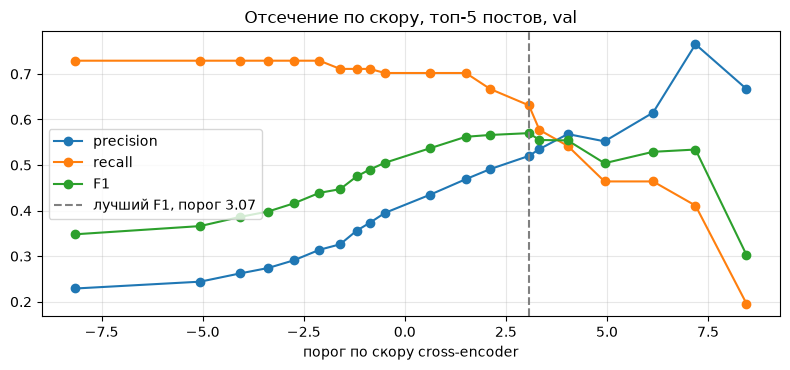

на test при этом пороге: {'порог': 3.07, 'precision': 0.556, 'recall': 0.521, 'F1': 0.538, 'негативных без выдачи, %': 67, 'вопросов с ответом без выдачи, %': 25}


,порог,precision,recall,F1,"негативных без выдачи, %","вопросов с ответом без выдачи, %"
0,-8.15,0.229,0.729,0.348,0,0
1,-5.06,0.244,0.729,0.366,0,0
2,-4.08,0.262,0.729,0.386,0,4
3,-3.38,0.274,0.729,0.398,0,4
4,-2.74,0.291,0.729,0.416,14,4
5,-2.11,0.314,0.729,0.439,14,4
6,-1.60,0.326,0.711,0.447,14,4
7,-1.19,0.356,0.711,0.475,14,11
8,-0.87,0.373,0.711,0.490,14,11
9,-0.49,0.395,0.702,0.505,14,11


In [13]:
def ce_scored(q, retriever=hybrid, pool=CE_POOL):
    cand = candidates(retriever, q, pool)[:pool]
    scores = ce.predict([(q, texts[i]) for i in cand], batch_size=32, show_progress_bar=False)
    order = np.argsort(-scores)
    posts, best = [], {}
    for j in order:
        d = chunk_doc[cand[j]]
        if d not in best:
            best[d] = float(scores[j])
            posts.append(d)
    return [(d, best[d]) for d in posts[:5]]

SCORED = {g['qid']: ce_scored(g['question']) for g in gold}

def at_threshold(qs, t):
    kept_total = kept_rel = 0
    recalls, empty_neg, empty_pos = [], [], []
    for g in qs:
        rel = {dup_map.get(d, d) for d in g['relevant_doc_ids']}
        kept = [d for d, s in SCORED[g['qid']] if s >= t]
        if not rel:
            empty_neg.append(not kept)
            continue
        empty_pos.append(not kept)
        recalls.append(len(rel & set(kept)) / len(rel))
        kept_total += len(kept)
        kept_rel += len(rel & set(kept))
    p, r = kept_rel / kept_total if kept_total else 0.0, float(np.mean(recalls))
    return {'порог': t, 'precision': round(p, 3), 'recall': round(r, 3), 'F1': round(2 * p * r / (p + r), 3) if p + r else 0.0,
            'негативных без выдачи, %': round(100 * np.mean(empty_neg)), 'вопросов с ответом без выдачи, %': round(100 * np.mean(empty_pos))}

all_scores = np.array([s for g in val_q for _, s in SCORED[g['qid']]])
THRESHOLDS = np.round(np.quantile(all_scores, np.linspace(0, 0.95, 20)), 2)
thr_table = pd.DataFrame([at_threshold(val_q, t) for t in THRESHOLDS])
best_t = float(thr_table.sort_values('F1', ascending=False).iloc[0]['порог'])

fig, ax = plt.subplots(figsize=(8, 3.8))
for col in ['precision', 'recall', 'F1']:
    ax.plot(thr_table['порог'], thr_table[col], marker='o', label=col)
ax.axvline(best_t, color='gray', ls='--', label=f'лучший F1, порог {best_t}')
ax.set_xlabel('порог по скору cross-encoder'); ax.set_title('Отсечение по скору, топ-5 постов, val'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print('на test при этом пороге:', at_threshold(test_q, best_t))
thr_table

Лучший F1 на пороге около 3. Precision вырастает с 0.23 до 0.52, recall падает с 0.73 до 0.63. Зато у 57% негативных вопросов выдача становится пустой, правда и у 21% нормальных тоже. Дальше чем выше порог, тем точнее, но теряем всё больше нужного. На test картина похожая. Так что порог полезен скорее как фильтр мусора перед генерацией.

Сравниваю реранкинг поверх dense и поверх hybrid:

In [14]:
rows = []
for name, retriever in [('dense', dense_only), ('hybrid', hybrid)]:
    before = summary(evaluate(retriever, val_q))
    after = summary(evaluate(ce_rerank(ce, retriever, CE_POOL), val_q))
    rows.append({'первичный поиск': name, **{f'{m} до': before[m] for m in MAIN}, **{f'{m} после CE': after[m] for m in MAIN},
                 'прирост NDCG@5': round(after['NDCG@5'] - before['NDCG@5'], 3)})
pd.DataFrame(rows)

,первичный поиск,P@5 до,R@5 до,NDCG@5 до,P@5 после CE,R@5 после CE,NDCG@5 после CE,прирост NDCG@5
0,dense,0.214,0.699,0.675,0.214,0.693,0.688,0.013
1,hybrid,0.236,0.743,0.713,0.229,0.729,0.719,0.006


Поверх dense прирост больше, потому что dense сам ставит нужное хуже, и cross-encoder'у есть что исправлять. Но hybrid с реранкингом всё равно лучше, чем dense с реранкингом.

## 4. LLM как реранкер

Даю LLM вопрос и N кандидатов, она возвращает порядок, остальная выдача после них остаётся как была. Иногда модель отвечала не по формату, начинала рассуждать или повторяла номера, тогда переспрашиваю.

In [15]:
LR_HEAD = 'Ниже вопрос пользователя и {n} фрагментов постов из Telegram-каналов про игры. Отсортируй фрагменты по тому, насколько они помогают ответить на вопрос, от самого полезного к наименее полезному. '
LR_TIES = 'Если несколько фрагментов одинаково полезны или одинаково бесполезны, оставь их в том порядке, в котором они даны. '
LR_TAIL = 'Верни только номера всех {n} фрагментов через запятую, например: 3, 1, 2. Без пояснений.\n\nВопрос: {q}\n\nФрагменты:\n{docs}'
LR_V3 = 'Ниже вопрос пользователя и {n} фрагментов постов из Telegram-каналов про игры. Оцени каждый фрагмент: 2 если он прямо отвечает на вопрос, 1 если он по теме и отвечает частично, 0 если не помогает. Верни только оценки всех {n} фрагментов в формате номер:оценка через запятую, например: 1:2, 2:0, 3:1. Без пояснений.\n\nВопрос: {q}\n\nФрагменты:\n{docs}'
LR_PROMPTS = {'v1': LR_HEAD + LR_TAIL, 'v2': LR_HEAD + LR_TIES + LR_TAIL, 'v3': LR_V3}
LR_VERSION = 'v1'

def lr_prompt(q, cand, version):
    docs = '\n\n'.join(f'[{j + 1}] ' + texts[i].replace('\n', ' ') for j, i in enumerate(cand))
    return LR_PROMPTS[version].replace('{n}', str(len(cand))).replace('{q}', q).replace('{docs}', docs)

def lr_order(text, n):
    if re.search(r'\d+\s*:\s*[012]', text):
        score = {int(j) - 1: int(v) for j, v in re.findall(r'(\d+)\s*:\s*([012])', text) if 0 < int(j) <= n}
        return sorted(range(n), key=lambda j: (-score.get(j, 0), j))
    order = []
    for x in re.findall(r'\d+', text):
        x = int(x) - 1
        if 0 <= x < n and x not in order:
            order.append(x)
    return order + [j for j in range(n) if j not in order]

STRICT = re.compile(r'\s*\d+(?:\s*,\s*\d+)*\s*\.?\s*')
STRICT_V3 = re.compile(r'\s*\d+\s*:\s*[012](?:\s*,\s*\d+\s*:\s*[012])*\s*\.?\s*')
def valid_list(text, n):
    if STRICT_V3.fullmatch(text):
        return sorted(int(j) for j in re.findall(r'(\d+)\s*:', text)) == list(range(1, n + 1))
    nums = re.findall(r'\d+', text)
    return bool(STRICT.fullmatch(text)) and len(nums) == n and len(set(nums)) == n

def lr_call(q, cand, run=0, version=None):
    prompt = lr_prompt(q, cand, version or LR_VERSION)
    o = llm('lr', prompt, 120 if (version or LR_VERSION) != 'v3' else 250, run)
    if valid_list(o['text'], len(cand)):
        return o
    fmt = 'оценок номер:оценка' if (version or LR_VERSION) == 'v3' else 'разных номеров'
    retry = llm('lr', prompt + f'\n\nОтвет должен быть только списком из {len(cand)} {fmt} через запятую, без текста.', 300, run)
    return {'text': retry['text'], 'in': o['in'] + retry['in'], 'out': o['out'] + retry['out'], 'sec': o['sec'] + retry['sec']}

def llm_rerank(retriever, n):
    def search(q):
        cand = retriever(q)
        o = lr_call(q, cand[:n])
        return [cand[j] for j in lr_order(o['text'], n)] + cand[n:]
    return search

Сначала стабильность: 20 пар из val прогоняю два раза при temperature 0 и смотрю, совпал ли порядок. Пробовал три промпта:
- v1: просто отсортируй фрагменты;
- v2: то же, но одинаково полезные фрагменты оставь как были;
- v3: поставь каждому фрагменту оценку 0, 1 или 2, а сортирую я сам.

In [16]:
DET_N = 10
det_q = [g['question'] for g in val_q if g['type'] != 'negative'][:20]
agreement = {}
for version in LR_PROMPTS:
    first = run_parallel(lambda q: lr_call(q, hybrid(q)[:DET_N], run=1, version=version), det_q)
    second = run_parallel(lambda q: lr_call(q, hybrid(q)[:DET_N], run=2, version=version), det_q)
    agreement[version] = np.mean([lr_order(a['text'], DET_N) == lr_order(b['text'], DET_N) for a, b in zip(first, second)])
    same_top5 = np.mean([set(lr_order(a['text'], DET_N)[:5]) == set(lr_order(b['text'], DET_N)[:5]) for a, b in zip(first, second)])
    print(f'промпт {version}: пар {len(det_q)} | полностью одинаковый порядок: {100 * agreement[version]:.0f}% | одинаковый топ-5: {100 * same_top5:.0f}%')
    for a, b, q in zip(first, second, det_q):
        if lr_order(a['text'], DET_N) != lr_order(b['text'], DET_N):
            print('   расхождение:', q[:50], '|', a['text'], '|', b['text'])
LR_VERSION = max(agreement, key=agreement.get)
print('дальше беру промпт', LR_VERSION)

промпт v1: пар 20 | полностью одинаковый порядок: 85% | одинаковый топ-5: 100%
   расхождение: До какого числа можно бесплатно забрать Bloons TD  | 1, 2, 3, 6, 9, 4, 5, 7, 10, 8 | 1, 2, 3, 9, 6, 4, 5, 7, 10, 8
   расхождение: Что Sony запатентовала в свём гейпаде DualSense? | 1, 2, 4, 6, 7, 3, 5, 9, 8, 10 | 1, 2, 4, 6, 7, 3, 9, 5, 8, 10
   расхождение: По подборкам сикдок в Steam, которые дйствуют до 2 | 9, 2, 1, 3, 10, 8, 5, 6, 7, 4 | 2, 9, 1, 3, 10, 8, 5, 6, 7, 4
промпт v2: пар 20 | полностью одинаковый порядок: 85% | одинаковый топ-5: 95%
   расхождение: Что Sony запатентовала в свём гейпаде DualSense? | 1, 2, 6, 4, 7, 3, 5, 9, 8, 10 | 1, 2, 4, 6, 3, 7, 9, 5, 8, 10
   расхождение: Демофест 3.0 VK Play количество игр заявки | 2, 1, 4, 3, 6, 5, 8, 10, 7, 9 | 2, 1, 4, 3, 6, 5, 8, 7, 9, 10
   расхождение: Насколько предзаказы GTA VI на PS5 опережают Xbox  | 1, 2, 3, 5, 4, 7, 8, 9, 6, 10 | 1, 2, 3, 5, 4, 7, 8, 6, 9, 10


промпт v3: пар 20 | полностью одинаковый порядок: 95% | одинаковый топ-5: 95%
   расхождение: Какие изменения в распространении игр планирует So | 1:1, 2:2, 3:1, 4:1, 5:2, 6:2, 7:1, 8:0, 9:0, 10:1 | 1:1, 2:2, 3:1, 4:1, 5:2, 6:1, 7:1, 8:0, 9:0, 10:1
дальше беру промпт v3


С первым промптом совпало 85%, это меньше нужных 90%. Модель иногда меняла местами соседние фрагменты, в одном вопросе даже первые два. Второй промпт не помог, тоже 85%. С третьим 95%, потому что одинаковые оценки я сортирую сам и перестановкам взяться неоткуда. Дальше беру его.

Теперь сколько кандидатов давать: 5, 10 или 20.

In [17]:
LR_N = [5, 10, 20]
for n in LR_N:
    run_parallel(lambda q, n=n: lr_call(q, hybrid(q)[:n]), [g['question'] for g in gold])
lr_rows = []
for n in LR_N:
    calls = [lr_call(g['question'], hybrid(g['question'])[:n]) for g in gold]
    lr_rows.append({'N кандидатов': n, **summary(evaluate(llm_rerank(hybrid, n), val_q), ['P@5', 'R@5', 'NDCG@5', 'MRR']),
                    'время LLM, с медиана': round(np.median([o['sec'] for o in calls]), 2), 'input токенов': round(np.mean([o['in'] for o in calls])),
                    'стоимость $ на запрос': round(np.mean([cost(o) for o in calls]), 4)})
lr_table = pd.DataFrame(lr_rows)
LR_BEST = int(lr_table.sort_values(['R@5', 'NDCG@5'], ascending=False).iloc[0]['N кандидатов'])
print('беру N:', LR_BEST)
lr_table

беру N: 10


,N кандидатов,P@5,R@5,NDCG@5,MRR,"время LLM, с медиана",input токенов,стоимость $ на запрос
0,5,0.236,0.743,0.728,0.754,1.23,944,0.0032
1,10,0.250,0.763,0.734,0.759,1.57,1671,0.0058
2,20,0.250,0.754,0.738,0.757,1.99,3126,0.0109


Качество растёт, но всё слабее, а цена почти удваивается на каждом шаге. На 5 модель может только переставить те же 5 чанков, поэтому Recall@5 не меняется. На 10 Recall@5 лучший (0.763), а на 20 уже чуть хуже и вдвое дороже. Беру 10.

## 5. Задержка по этапам

Меряю на 100 запросах время каждого этапа: перефразировка, эмбеддинг запроса, поиск, cross-encoder и LLM-реранкер. В таблице медиана и p95 по этапам и в сумме, и какой этап самый долгий.

In [18]:
base_list = {q: hybrid(q) for q in TIMING_QUERIES}
mq_list = {q: multi_query(q) for q in TIMING_QUERIES}
ce_base = {q: candidates(hybrid, q, CE_POOL)[:CE_POOL] for q in TIMING_QUERIES}
ce_mq = {q: candidates(multi_query, q, CE_POOL)[:CE_POOL] for q in TIMING_QUERIES}
run_parallel(lambda q: lr_call(q, base_list[q][:LR_BEST]), TIMING_QUERIES)
run_parallel(lambda q: lr_call(q, mq_list[q][:LR_BEST]), TIMING_QUERIES)

def encode_time(qs):
    t0 = time.perf_counter()
    frida.encode(qs, prompt='search_query: ', batch_size=32, normalize_embeddings=True, convert_to_numpy=True, show_progress_bar=False)
    return 1000 * (time.perf_counter() - t0)

def search_time(variants):
    t0 = time.perf_counter()
    rrf([l for v in variants for l in (bm25_list(v, DEPTH), chroma_query(v, DEPTH))], DEPTH)
    return 1000 * (time.perf_counter() - t0)

def ce_time(q, cand):
    t0 = time.perf_counter()
    ce.predict([(q, texts[i]) for i in cand], batch_size=32, show_progress_bar=False)
    return 1000 * (time.perf_counter() - t0)

def live_times():
    encode_time(['прогрев'])
    out = {}
    for q in TIMING_QUERIES:
        variants = [q] + mq_variants(q)
        out[q] = {'emb': encode_time([q]), 'search': search_time([q]), 'emb_mq': encode_time(variants), 'search_mq': search_time(variants),
                  'ce': ce_time(q, ce_base[q]), 'ce_mq': ce_time(q, ce_mq[q])}
    return out

LIVE = measured('latency_live', live_times)
STAGES = ['трансформация', 'эмбеддинг запроса', 'поиск', 'cross-encoder', 'LLM-реранкер']
prof = {name: [] for name in ['baseline', '+ multi-query', '+ cross-encoder', '+ LLM-реранкер', '+ multi-query + cross-encoder', '+ multi-query + LLM-реранкер']}
for q in TIMING_QUERIES:
    mq = llm('mq', MQ_PROMPT.replace('{q}', q), 300)
    t = LIVE[q]
    t_ce, t_ce_mq = t['ce'], t['ce_mq']
    lr, lr_mq = lr_call(q, base_list[q][:LR_BEST]), lr_call(q, mq_list[q][:LR_BEST])
    base = {'эмбеддинг запроса': t['emb'], 'поиск': t['search']}
    with_mq = {'трансформация': 1000 * mq['sec'], 'эмбеддинг запроса': t['emb_mq'], 'поиск': t['search_mq']}
    prof['baseline'].append({**base, 'cost': 0.0})
    prof['+ multi-query'].append({**with_mq, 'cost': cost(mq)})
    prof['+ cross-encoder'].append({**base, 'cross-encoder': t_ce, 'cost': 0.0})
    prof['+ LLM-реранкер'].append({**base, 'LLM-реранкер': 1000 * lr['sec'], 'cost': cost(lr)})
    prof['+ multi-query + cross-encoder'].append({**with_mq, 'cross-encoder': t_ce_mq, 'cost': cost(mq)})
    prof['+ multi-query + LLM-реранкер'].append({**with_mq, 'LLM-реранкер': 1000 * lr_mq['sec'], 'cost': cost(mq) + cost(lr_mq)})

rows = []
for name, items in prof.items():
    df = pd.DataFrame(items).reindex(columns=STAGES + ['cost'])
    total = df[STAGES].fillna(0.0).sum(axis=1)
    med = df[STAGES].median()
    stage_cells = {f'{s}, мс': '-' if df[s].isna().all() else f'{df[s].median():.1f} / {np.percentile(df[s], 95):.1f}' for s in STAGES}
    rows.append({'конфигурация': name, **stage_cells, 'итого медиана, мс': round(total.median()), 'итого p95, мс': round(np.percentile(total, 95)),
                 'узкое место': med.idxmax(), 'стоимость $ на запрос': round(df['cost'].mean(), 4)})
latency_table = pd.DataFrame(rows)
latency_table

,конфигурация,"трансформация, мс","эмбеддинг запроса, мс","поиск, мс","cross-encoder, мс","LLM-реранкер, мс","итого медиана, мс","итого p95, мс",узкое место,стоимость $ на запрос
0,baseline,-,48.4 / 55.2,4.8 / 7.5,-,-,53,63,эмбеддинг запроса,0.0000
1,+ multi-query,2218.5 / 3163.1,74.2 / 118.5,15.3 / 20.6,-,-,2309,3252,трансформация,0.0019
2,+ cross-encoder,-,48.4 / 55.2,4.8 / 7.5,69.7 / 81.6,-,123,141,cross-encoder,0.0000
3,+ LLM-реранкер,-,48.4 / 55.2,4.8 / 7.5,-,1596.0 / 2612.2,1650,2661,LLM-реранкер,0.0059
4,+ multi-query + cross-encoder,2218.5 / 3163.1,74.2 / 118.5,15.3 / 20.6,70.5 / 80.6,-,2382,3324,трансформация,0.0019
5,+ multi-query + LLM-реранкер,2218.5 / 3163.1,74.2 / 118.5,15.3 / 20.6,-,1722.0 / 2395.2,4052,5451,трансформация,0.0078


В baseline дольше всего считается эмбеддинг запроса, а сам поиск быстрый, весь запрос около 50 мс. С cross-encoder самым долгим становится он, но это всё равно 120 мс. А с LLM всё остальное уже не важно: перефразировка около 2 секунд, реранкер около 1.6, и запрос растягивается до 1.7-4 секунд.

## 6. Итоговая таблица

Все конфигурации по порядку, метрики на val и test, время и цена на запрос. Под таблицей график, время против Recall@5.

In [19]:
CONFIGS = {
    'baseline': hybrid,
    '+ multi-query': multi_query,
    '+ cross-encoder': ce_rerank(ce, hybrid, CE_POOL),
    '+ LLM-реранкер': llm_rerank(hybrid, LR_BEST),
    '+ multi-query + cross-encoder': ce_rerank(ce, multi_query, CE_POOL),
    '+ multi-query + LLM-реранкер': llm_rerank(multi_query, LR_BEST),
}
lat = latency_table.set_index('конфигурация')
rows = []
for name, search in CONFIGS.items():
    on_val, on_test = summary(evaluate(search, val_q)), summary(evaluate(search, test_q))
    rows.append({'конфигурация': name, **{f'val {m}': on_val[m] for m in MAIN}, **{f'test {m}': on_test[m] for m in MAIN},
                 'медиана, мс': lat.loc[name, 'итого медиана, мс'], 'p95, мс': lat.loc[name, 'итого p95, мс'], 'стоимость $ на запрос': lat.loc[name, 'стоимость $ на запрос']})
final_table = pd.DataFrame(rows)
final_table

,конфигурация,val P@5,val R@5,val NDCG@5,test P@5,test R@5,test NDCG@5,"медиана, мс","p95, мс",стоимость $ на запрос
0,baseline,0.236,0.743,0.713,0.250,0.771,0.759,53,63,0.0000
1,+ multi-query,0.229,0.698,0.655,0.250,0.771,0.709,2309,3252,0.0019
2,+ cross-encoder,0.229,0.729,0.719,0.267,0.792,0.681,123,141,0.0000
3,+ LLM-реранкер,0.250,0.763,0.734,0.267,0.792,0.761,1650,2661,0.0059
4,+ multi-query + cross-encoder,0.236,0.733,0.722,0.250,0.771,0.671,2382,3324,0.0019
5,+ multi-query + LLM-реранкер,0.250,0.739,0.732,0.267,0.792,0.744,4052,5451,0.0078


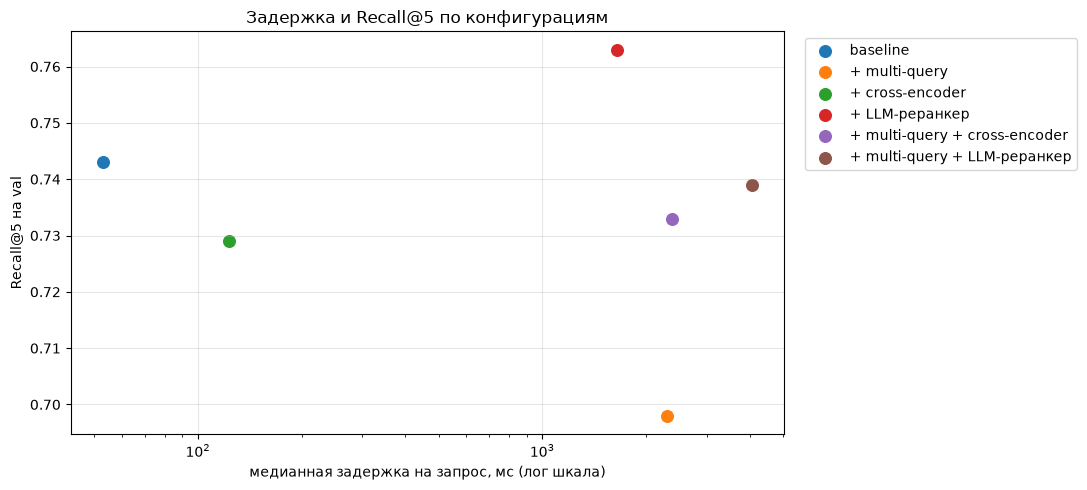

In [20]:
fig, ax = plt.subplots(figsize=(11, 5))
for _, r in final_table.iterrows():
    ax.scatter(r['медиана, мс'], r['val R@5'], s=70, label=r['конфигурация'])
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1))
ax.set_xscale('log'); ax.set_xlabel('медианная задержка на запрос, мс (лог шкала)'); ax.set_ylabel('Recall@5 на val')
ax.set_title('Задержка и Recall@5 по конфигурациям'); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## Итоги КТ4

Multi-query не зашёл: на абстрактных помогает, на составных сильно мешает, в среднем хуже и медленнее. Cross-encoder поверх hybrid почти ничего не даёт, разве что его скор можно использовать как порог от мусора. Recall@5 на val поднял только LLM-реранкер, и на test он тоже выше baseline. Если добавить перед реранкерами multi-query, с cross-encoder почти ничего не меняется, а LLM-реранкер даже теряет в Recall@5, и время растёт на 2 с лишним секунды.

Для КТ5 смотрю на график. Выше baseline там только LLM-реранкер, остальное ниже. Он добавляет примерно 1.6 секунды и $0.006 на запрос, зато нужный пост чаще попадает в топ-5, а именно топ-5 пойдёт в контекст для ответа. Генерация в КТ5 это тоже вызов LLM на пару секунд, так что лишние полторы секунды не критично. Беру baseline с LLM-реранкером на 10 кандидатах.